# 00 · The story: does Hull and White's minimum-variance delta hedge SPX options better?

*A pre-registered model validation on SPX option quotes, 2011–2023.*

This notebook tells the project's whole story, in the order of the executive summary ([`EXECUTIVE_SUMMARY.md`](../EXECUTIVE_SUMMARY.md)), with more detail. Every number it quotes is computed below from the committed tables in `results/`, so the story can be checked line by line. Each section names the notebooks that hold the detail:

| Section | Detail in |
|---|---|
| Bottom line | this notebook |
| 1. The problem | this notebook; `analysis_plan.md` §6 |
| 2. Data | 01 (audit and attrition), 02 (forwards, implied volatilities, Greeks); `DATA.md` |
| 3. Methodology | 03 (the rehearsal and the dry run); `analysis_plan.md` §§5–10 |
| 4.1 The confirmatory test | 04 (the 2020 verdict), 05 (its robustness and breakdown) |
| 4.2 Years and stress episodes | 06 (the 2011–2023 walk-forward), 09 (stress episodes), 07 (SPY) |
| 4.3 Complex against simple rules | 06 (the scaling rules), 08 (the challengers) |
| 4.4 The level and the assumption checks | 09 (level, shape, stability, maturity), 08 (polynomial degree), 03 (the checks made before 2020) |
| 4.5 Extensions and published benchmarks | 10 (books, held positions, data starvation), 11 (stocks and ETFs), 08 (short-dated options), 09 (the published Gains) |
| 5. Financial interpretation | 05 (where the error comes from), 06, 09, 10 |
| 6. Assumptions, limitations and failure modes | 04, 05, 08, 09, 11 |
| 7. Reproducibility | `REPRODUCING.md` |

The finance is explained where it first appears, with the boot camp's lectures cited where they cover it.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
R = ROOT / "results"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})
from IPython.display import Image, display
CP = {"C": "calls", "P": "puts"}


def fmt(r, d=3):
    # A Gain with its 95% session-block bootstrap interval; * marks an interval that excludes 0
    star = " *" if (r.lo > 0 or r.hi < 0) else ""
    return f"{r.gain:+.{d}f} [{r.lo:+.2f}, {r.hi:+.2f}]{star}"


# The SPX walk-forward, 2011-2023: every rule's yearly Gain with 12-, 36- and 60-month fits
G = pd.read_csv(R / "walkforward/gains_by_year.csv")  # R1-R4
WF = pd.concat([G,
                pd.read_csv(R / "walkforward/degrees_by_year.csv"),  # P0-P8 and PCV
                pd.read_csv(R / "walkforward/r9_r11_by_year.csv").query("rule != 'R2'"),  # LightGBM R9-R11
                pd.read_csv(R / "walkforward/r5_r8_by_year.csv").query("rule != 'R2'").drop(columns="sample")],  # R5, R6, R8
               ignore_index=True)


def wf(rule, base, window=12):
    return WF[(WF.rule == rule) & (WF.base == base) & (WF.window == window)].sort_values(["year", "cp"])


def median_1523(rule, base, window=12):
    # The median yearly Gain over 2015-2023, the span common to all three windows
    x = wf(rule, base, window)
    return x[x.year.between(2015, 2023)].groupby("cp").gain.median()

## Bottom line

**The question.** Does adjusting the Black–Scholes delta for changing volatility improve daily SPX option hedges? A dealer hedges each option by holding delta units of the index. The Black–Scholes delta treats volatility as fixed, although implied volatility, the volatility consistent with an option's price, tends to rise when the index falls. Hull and White's minimum-variance delta corrects for this response, using monthly regressions on past prices. Its **Gain** is the fraction of the Black–Scholes delta's squared one-day hedging error that it removes.

**The pre-registered SPX 2020 test is inconclusive.** The minimum-variance delta removed 18.5% of the squared error for calls and 12.0% for puts. But the March 2020 crash leaves 95% intervals spanning about −0.4 to +0.46, so neither an improvement nor a loss is established. The verdict rule was committed before any test-year number was computed. All 11 pre-specified robustness variants preserve the verdict.

**Repeated out of sample over 2011–2023,** with monthly fits on the preceding 12 months, the correction usually helps. Its median yearly Gain over 2015–2023, the span common to all fitting windows, is 0.12 for calls and 0.10 for puts. In no year is it significantly worse than Black–Scholes. Its advantage disappears in 2022–2023, as implied volatility became less responsive to index moves.

**Simpler rules do almost as well.** One fitted constant correction gives essentially the same Gain as the three-coefficient form. Machine-learning corrections add no material improvement, and two fail badly in the crash. Ruf and Wang's fixed 0.9/1.1 scaling, an unfitted rule of thumb read off their results, matches the minimum-variance delta's median Gain but fails in 2022–2023.

**Figure 1** (below) carries the stability evidence: the yearly Gain of the minimum-variance delta over the Black–Scholes delta, for calls and puts, with 12-, 36- and 60-month fits and 95% session-block bootstrap intervals. Grey marks the clean held-out years (2011–2013 and 2021–2023), which no earlier step had touched; orange marks the pre-registered test year, 2020.

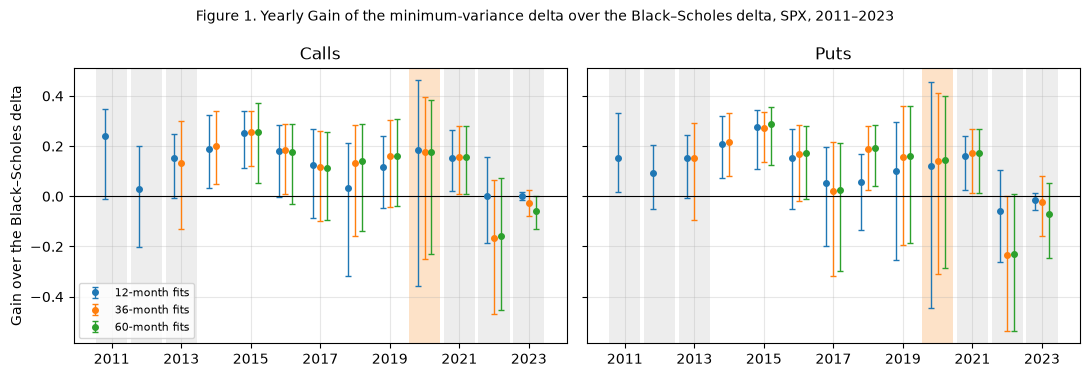

In [2]:
x = G[(G.rule == "R2") & (G.base == "R1")]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, cp in zip(axes, "CP"):
    for yr in (2011, 2012, 2013, 2021, 2022, 2023):  # the clean held-out years
        ax.axvspan(yr - 0.45, yr + 0.45, color="0.93", zorder=0, lw=0)
    ax.axvspan(2019.55, 2020.45, color="#fde2c8", zorder=0, lw=0)  # the pre-registered test year
    for W, c, off in ((12, "#1f77b4", -0.2), (36, "#ff7f0e", 0.0), (60, "#2ca02c", 0.2)):
        z = x[(x.cp == cp) & (x.window == W)]
        ax.errorbar(z.year + off, z.gain, yerr=[z.gain - z.lo, z.hi - z.gain], fmt="o", ms=4, color=c, capsize=2, lw=1, label=f"{W}-month fits")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(CP[cp].capitalize()); ax.set_xticks(range(2011, 2024, 2))
axes[0].set_ylabel("Gain over the Black–Scholes delta"); axes[0].legend(fontsize=8, loc="lower left")
plt.suptitle("Figure 1. Yearly Gain of the minimum-variance delta over the Black–Scholes delta, SPX, 2011–2023", fontsize=10)
plt.tight_layout(); plt.show()

## 1. The problem

**A delta hedge** (Lectures 6–8). A dealer who holds one option and shorts h units of the index from one close to the next earns Δf − h·ΔS, where Δf is the option's price change and ΔS the index's. The Black–Scholes delta, δ_BS = ∂f/∂S, is the h that removes the index risk *if volatility does not move*. Lecture 7 builds this hedge and Lecture 8 backtests it.

**Why volatility matters.** Implied volatility moves, and on average it moves *with* the index: it tends to rise when the index falls (Lecture 11's SPY smiles show the related skew across strikes). An option's sensitivity to volatility is its vega, ν = ∂f/∂σ (Lecture 6). If a 1% fall in the index raises implied volatility by a predictable amount, part of the option's vega exposure is really index exposure, and a hedge can neutralize it.

**Hull and White's minimum-variance delta** does that. It is the right-hand side of their equation (2):

$$
\delta_{\mathrm{MV}}\approx\delta_{\mathrm{BS}}+\nu_{\mathrm{BS}}\frac{\partial E[\sigma_{\mathrm{imp}}]}{\partial S}.
$$

Here $S$ is the index level and $\sigma_{\mathrm{imp}}$ is implied volatility. To first order, Δf ≈ δ_BS·ΔS + ν·Δσ, so the h that minimizes the variance of Δf − h·ΔS is δ_BS plus ν times the regression slope of Δσ on ΔS: the correction hedges the *expected* volatility response to an index move. The part of the volatility move that is unrelated to the index stays unhedged, as it must for any delta.

**The main rules,** simplest first:
1. the Black–Scholes delta, the benchmark;
2. the fixed 0.9/1.1 scaling: 0.9 times delta for calls, 1.1 times delta for puts;
3. the fitted scaling, $a\delta$, with $a$ fitted monthly;
4. the minimum-variance delta, with three coefficients fitted monthly.

**The exploratory challengers** are a constant correction; polynomials in delta of degrees 0–8, and a separate rule whose degree is selected by validation; a relaxed Hull–White rule with a free delta multiplier; Ruf and Wang's delta–vega–vanna regression; and LightGBM corrections using delta alone or market features.

The tables in `results/` and the other notebooks name the rules by code:

| Rule in the story | Code | Hedge ratio | Coefficients fitted per option type |
|---|---|---|---|
| No hedge (reference for effectiveness) | R0 | 0 | — |
| Black–Scholes delta | R1 | δ, at the option's own implied volatility | 0 |
| Fixed 0.9/1.1 scaling (Ruf and Wang's rule of thumb) | R3 | 0.9·δ for calls, 1.1·δ for puts | 0 |
| Fitted scaling | R4 | a·δ | 1 |
| Constant correction | P0 | δ + c·ν/(S√T) | 1 |
| Minimum-variance delta (Hull and White) | R2 | δ + ν/(S√T)·(a + bδ + cδ²) | 3 |
| Polynomial of degree k in delta | P0–P8 | δ + ν/(S√T)·p_k(δ); P2 spans the same functions as R2 | k + 1 |
| Degree chosen by validation | PCV | P_k, with k chosen inside each training window | — |
| Relaxed Hull–White | R5 | a₀·δ + ν/(S√T)·(a + bδ + cδ²) | 4 |
| Ruf and Wang's delta–vega–vanna regression | R6 | a·δ + b·ν/S + c·vanna | 3 |
| LightGBM on delta alone | R9 (from scratch), R11 (boosted from R2) | δ + ν/(S√T)·h(δ) | tuned |
| LightGBM on market features | R10 (from scratch), R8 (boosted from R2) | δ + ν/(S√T)·h(z) | tuned |

The market features z are delta, log maturity, the option's position on its smile, the at-the-money implied volatility, 20-day realized volatility and the 5-day index return (`analysis_plan.md` §6). R7, a regression tree, was specified but withdrawn from the submission (`analysis_plan.md` §15, 2026-11-06), which is why the codes skip it.

**Why it matters.** The question matters to dealers who hedge daily, and to the teams that validate their models. Black–Scholes leaves the volatility response unhedged. Why implied volatility rises when the index falls is debated: the *leverage* explanation (a falling stock price raises a firm's debt-to-equity ratio and so its volatility) against *volatility feedback* (higher volatility raises the returns investors require, which lowers prices). Hull and White read the evidence as favouring volatility feedback. For hedging, what matters is how large and how stable the response is, and that is what this study measures.

## 2. Data

| Data | Source | Used for |
|---|---|---|
| SPX and SPY end-of-day option quotes, 2010–2023 | OptionsDX | One row per quote date, expiry and strike, with the call and the put side by side |
| AAPL, NVDA, TSLA, QQQ and SLV option quotes, 2016–2023 | OptionsDX | The extension to stocks and ETFs (§4.5) |
| S&P 500 closes | FRED (Cboe before 2016-10) | The index level for SPX |
| SPY closes | Nasdaq (Stooq before 2016-11, with its dividend adjustment reversed) | SPY's level |
| The five stocks' and ETFs' levels | the vendor's near-close snapshot | No official close was in hand |
| Dividends | SSGA for SPY; Nasdaq for AAPL, NVDA and QQQ | TSLA and SLV pay none |
| Rates and the S&P 500's dividend yield | none: each expiry's forward and discount factor are read from put–call parity on the SPX quotes (notebook 02) | Pricing, implied volatilities and Greeks |

**The unit of observation is a pair:** one contract at one NYSE session's close (day one), and the same contract at the next session's close (day two). The hedge is set on day one and judged on day two, which is Lecture 7's discrete hedge cut to one period.

**The sample** requires at least 14 days to expiry, an absolute delta of 0.05–0.95 (Hull and White's filters, which keep both in- and out-of-the-money options), and trading on day one (Ruf and Wang's filter, since an untraded quote may be stale).

**The vendor's data needed care** (notebook 01; every rule is in `DATA.md`):
- **Volume.** Through 2021 the vendor never records a volume above 999, and an empty volume can mean 1,000 or more contracts traded. An empty volume with a positive last-trade price is read as traded. A naive "volume > 0" filter would drop the busiest contracts.
- **Timing.** The option quotes are synchronous with neither the official close nor the vendor's own index snapshot (their parity-implied index level sits a median 3.3 bp from the close in 2019–2020). Two sensitivities use the other levels (§4.1).
- **Calendar.** Pairs are formed across NYSE sessions, not the vendor's dates: 35 SPX sessions are missing from the files, and 12 holiday rows are after-close snapshots of the previous session.
- **April 2019.** On 2019-04-04 to 04-16 the vendor's expiry stamps shift by a day; pairs touching the window are excluded, without repair.

In [3]:
d20 = pd.read_csv(R / "2020/descriptives.csv").query("rule == 'R1'").set_index("cp").pairs
print(f"SPX 2020 pairs: {d20.sum():,} ({d20['C']:,} calls, {d20['P']:,} puts)")
print(f"SPX 2011-2023 pairs in the 12-month walk-forward: {wf('R2', 'R1').pairs.sum():,}")
cols = ["ok", "one_sided_next", "vendor_missing_session"]
st = pd.read_csv(R / "attrition/by_status.csv")  # its "2020" rows exclude the stress period, which has its own rows
st["period"] = st.period.replace({"2020": "2020, outside the stress period", "stress": "2020, stress period"})
whole = st[st.period.str.startswith("2020")].groupby("cp", as_index=False)[cols].sum().assign(period="2020, whole year")
st = pd.concat([st, whole]).set_index(["period", "cp"])
st["usable share"] = st.ok / st[cols].sum(axis=1)
st.round(4)

SPX 2020 pairs: 1,057,455 (489,199 calls, 568,256 puts)
SPX 2011-2023 pairs in the 12-month walk-forward: 7,644,088


ok  one_sided_next  vendor_missing_session  usable share
period                          cp                                                              
2019                            C   250230               6                    3619        0.9857
                                P   323033               1                    5024        0.9847
2020, outside the stress period C   386467              42                    5995        0.9846
                                P   436087              36                    6778        0.9846
2020, stress period             C   102732             349                       0        0.9966
                                P   132169             363                       0        0.9973
2020, whole year                C   489199             391                    5995        0.9871
                                P   568256             399                    6778        0.9875

**Reading.** In 2020, 98.7% of eligible pairs have a usable day-two quote (98.5% in 2019). Nearly all the rest fall on sessions the vendor lacks entirely, which are ordinary days; within the stress period no session is missing, and vanished bids (`one_sided_next`) are 0.3% of pairs. Results are conditional on a usable day-two quote, and the vanished quotes are stress-tested in §4.1. Detail: notebook 01.

## 3. Methodology

**The fitted rule** is Hull and White's equation (5):

$$
\delta_{\mathrm{MV}}=\delta_{\mathrm{BS}}+\frac{\nu_{\mathrm{BS}}}{S\sqrt{T}}\left(a+b\delta_{\mathrm{BS}}+c\delta_{\mathrm{BS}}^2\right).
$$

Here $T$ is the time to expiry in years. The $1/S$ factor makes volatility respond to index *returns* rather than to point moves. The $1/\sqrt{T}$ factor is Hull and White's empirical maturity scaling: short-dated implied volatilities move more. The quadratic lets the correction vary across strikes. Least squares fits the coefficients separately for calls and puts.

**Inputs.** Each expiry's forward and discount factor come from put–call parity at the mid quotes, so no rate or dividend yield is assumed. Implied volatilities come from the boot camp's Lecture 12 solver, and the Greeks are Black–Scholes at each option's own implied volatility (notebook 02).

**The error and the Gain.** For a hedge ratio $h$, the error is $e=(\Delta f-h\Delta S)/S$, where $\Delta f$ is the option's price change and $S$ the day-one index level. The Gain of a rule is $1-\mathrm{SSE}(\mathrm{rule})/\mathrm{SSE}(\mathrm{Black\text{–}Scholes})$, using sums of squared errors on identical pairs. Since the root-mean-square (RMS) error scales as $\sqrt{1-\text{Gain}}$, a Gain of 0.10 means 10% less squared error, or about 5% lower RMS error (computed below).

**The chronological protocol.** Monthly fits use trailing 12-month windows, with 36- and 60-month alternatives. Each fit hedges only the following month, and training pairs must end before the test month starts, so no fit sees its own outcomes.

**Before 2020 was opened,** a rehearsal on 2018–2019 and a dry run of the test script on 2019 checked the code and the model's form (notebook 03). The analysis plan, `analysis_plan.md`, was committed (77b030e) before any test-year number was computed; it fixed the endpoints, the verdict table and the thresholds ("material" means a Gain of at least 0.05).

**The walk-forward** repeats this chronological protocol over 2011–2023. Its untouched years, 2011–2013 and 2021–2023, are the clean held-out evidence; the other years had been used for fitting, rehearsal or the test before the walk-forward ran (the ledger below).

**Inference by session, not by option.** Bootstrap intervals resample trading days rather than options, because all options on a day share that day's index move: a circular block bootstrap of sessions, blocks of 10, 10,000 draws (plan §9). Ordinary standard errors that treat options as independent are 4.5–34 times too small for the rehearsal's coefficients (notebook 03). Yearly and episode significance is pointwise and not adjusted for multiple comparisons.

**The exploratory analyses** are all descriptive, and most were specified after 2020 had been seen. They cover the additional rules, an SPY replication, parameter stability, the polynomial degree and the maturity scaling, the correction's level and shape, the published benchmarks, books, 5- and 10-day held positions, reduced training data, short-dated options, and five stocks and ETFs. Stress episodes are defined from the S&P 500 close alone: 20-day realized volatility above 25%, or a peak-to-trough drawdown of at least 10%. Episode Gains use the walk-forward's fits, and stress and calm sessions are compared by year.

In [4]:
for g in (0.05, 0.10, 0.15, 0.25):
    print(f"Gain {g:.2f}: RMS error lower by {1 - np.sqrt(1 - g):.1%}")
with pd.option_context("display.max_colwidth", 140):
    display(pd.read_csv(R / "year_ledger.csv").head(8)[["years", "actual_exposure", "date"]])  # the core runs; later rows log the extensions

Gain 0.05: RMS error lower by 2.5%
Gain 0.10: RMS error lower by 5.1%
Gain 0.15: RMS error lower by 7.8%
Gain 0.25: RMS error lower by 13.4%


,years,actual_exposure,date
0,2010,fit-only: the walk-forward's first windows,2026-11-04T02:50
1,2011-2013,evaluated: the walk-forward (clean held-out years for W12 and W36),2026-11-04T02:50
2,2014,fit-only: the 2019 dry run's W60 fit (not a planned exposure),2026-11-04
3,2015-2017,fit-only: W36/W60 fits for 2020 (2015-2017 also fit the 2019 dry run's W36/W60),2026-11-04
4,2018,evaluated: rehearsal 2018-07 to 12 (6-month windows),2026-11-04
5,2019,evaluated: rehearsal 2019-07 to 12; tuned: R8 (60 trials per type); evaluated: dry run of the test-year script (all of 2019; pairs endin...,2026-11-04
6,2020,evaluated: unblinding run (plan 77b030e; implementation b661d6a),2026-11-04T02:37
7,2021-2023,evaluated: the walk-forward (clean held-out years),2026-11-04T02:50


## 4. Principal findings

### 4.1 The confirmatory test (detail: notebooks 04 and 05)

The pre-registered verdict for 2020 is **Inconclusive**: neither option type's 95% lower bound is above zero. The plan's hypothesis H1 needed both lower bounds of the Gain over Black–Scholes above zero. The minimum-variance delta is not distinguished from either scaling rule. The first row of the table is the primary analysis; the other 11 are the pre-specified robustness variants.

In [5]:
v = pd.read_csv(R / "2020/verdict.csv")
iv = lambda g, l, h: [f"{a:+.3f} [{b:+.2f}, {c:+.2f}]" for a, b, c in zip(g, l, h)]
t = pd.DataFrame({"variant": v.variant, "verdict": v.verdict,
                  "calls: Gain [95%]": iv(v.G_C, v.G_C_lo, v.G_C_hi), "puts: Gain [95%]": iv(v.G_P, v.G_P_lo, v.G_P_hi),
                  "calls against R3 / R4": v.C_vs_R3 + " / " + v.C_vs_R4, "puts against R3 / R4": v.P_vs_R3 + " / " + v.P_vs_R4})
print(f"primary: {v.verdict[0]}; the {len(v) - 1} robustness variants: {v.verdict[1:].value_counts().to_dict()}")
t

primary: Inconclusive; the 11 robustness variants: {'Inconclusive': 11}

,variant,verdict,calls: Gain [95%],puts: Gain [95%],calls against R3 / R4,puts against R3 / R4
0,primary,Inconclusive,"+0.185 [-0.36, +0.46]","+0.120 [-0.45, +0.46]",not distinguished / not distinguished,not distinguished / not distinguished
1,A,Inconclusive,"+0.147 [-0.40, +0.46]","+0.219 [-0.55, +0.55]",not distinguished / not distinguished,not distinguished / not distinguished
2,B,Inconclusive,"+0.178 [-0.38, +0.46]","+0.119 [-0.41, +0.45]",not distinguished / not distinguished,not distinguished / not distinguished
3,P-bid,Inconclusive,"+0.149 [-0.25, +0.37]","+0.101 [-0.32, +0.37]",not distinguished / not distinguished,not distinguished / not distinguished
4,P-ask,Inconclusive,"+0.140 [-0.25, +0.39]","+0.100 [-0.36, +0.41]",not distinguished / not distinguished,not distinguished / not distinguished
5,F,Inconclusive,"+0.178 [-0.09, +0.33]","+0.145 [-0.13, +0.32]",not distinguished / not distinguished,R2 beats / R2 beats
6,W36,Inconclusive,"+0.178 [-0.25, +0.40]","+0.142 [-0.31, +0.41]",not distinguished / not distinguished,not distinguished / not distinguished
7,W60,Inconclusive,"+0.176 [-0.23, +0.38]","+0.144 [-0.29, +0.40]",not distinguished / not distinguished,not distinguished / not distinguished
8,S3,Inconclusive,"+0.095 [-0.36, +0.41]","-0.028 [-0.48, +0.38]",not distinguished / not distinguished,not distinguished / not distinguished
9,rest of 2020,Inconclusive,"+0.126 [-0.24, +0.34]","+0.161 [-0.19, +0.34]",not distinguished / R2 beats,not distinguished / not distinguished


**The variants.** A: the index level implied by the options themselves (the parity forward of the nearest expiry). B: the vendor's 16:00 index snapshot. P-bid, P-ask: options marked at the bid or the ask instead of the mid. F: coefficients frozen at one 2019 fit. W36, W60: 36- and 60-month windows. S3: only quotes with a relative spread of at most 5%. Rest of 2020: leaving out the stress period, 24 February to 30 April. Endpoint low and high: the pairs whose day-two bid vanished, valued at the low and the high end of their no-arbitrage band. "R2 beats" in a comparison column means the minimum-variance delta beat that scaling rule in that variant; it happens three times, never in the primary.

**The verdict is hard to move; the point Gains are not.** With intervals this wide, no plausible variant could have changed the verdict, so its robustness says little on its own. The point Gains move more: the spread screen gives 0.095 / −0.028, the options' own index level 0.147 / 0.219, and bid or ask marks about 0.15 / 0.10. **A pre-registered timing diagnostic** (plan §8): from the primary to sensitivity A, the call Gain falls by 0.038 and the put Gain rises by 0.099. Changes in opposite directions are consistent with the timing mismatch between the option quotes and the close, though they do not identify it.

**The four main rules in 2020, and across years.** Gains are over the Black–Scholes delta. The constant correction was not a 2020 test-year rule; its 2020 values come from the walk-forward, which uses the same 12-month fits as the 2020 test.

In [6]:
g20 = pd.read_csv(R / "2020/gains.csv").query("variant == 'primary' and base == 'R1'")
rows = []
for name, rule, k in [("Fixed 0.9/1.1 scaling (Ruf and Wang's rule of thumb)", "R3", 0), ("Fitted scaling a·δ", "R4", 1),
                      ("Constant correction", "P0", 1), ("Minimum-variance delta (Hull and White)", "R2", 3)]:
    src = wf(rule, "R1").query("year == 2020") if rule == "P0" else g20[g20.rule == rule]
    m = median_1523(rule, "R1")
    rows.append({"hedge rule": name, "code": rule, "coefficients fitted": k,
                 "SPX 2020, calls": fmt(src[src.cp == "C"].iloc[0]), "SPX 2020, puts": fmt(src[src.cp == "P"].iloc[0]),
                 "median yearly Gain 2015-2023, calls / puts (12-month fits)": f"{m['C']:.3f} / {m['P']:.3f}"})
pd.DataFrame(rows)

,hedge rule,code,coefficients fitted,"SPX 2020, calls","SPX 2020, puts","median yearly Gain 2015-2023, calls / puts (12-month fits)"
0,Fixed 0.9/1.1 scaling (Ruf and Wang's rule of ...,R3,0,"+0.181 [-0.13, +0.34]","+0.021 [-0.30, +0.23]",0.125 / 0.099
1,Fitted scaling a·δ,R4,1,"+0.151 [-0.32, +0.36]","-0.076 [-0.52, +0.22]",0.120 / 0.060
2,Constant correction,P0,1,"+0.190 [-0.32, +0.46]","+0.120 [-0.44, +0.46]",0.119 / 0.105
3,Minimum-variance delta (Hull and White),R2,3,"+0.185 [-0.36, +0.46]","+0.120 [-0.45, +0.46]",0.124 / 0.100


**Perspective.** The numbers below put the 2020 Gains in context: how much Black–Scholes already does, what the improvement is worth in dollars, and how concentrated the year's error is.

In [7]:
d = pd.read_csv(R / "2020/descriptives.csv").set_index(["cp", "rule"])
for cp in "CP":
    r1, r2 = d.loc[(cp, "R1")], d.loc[(cp, "R2")]
    top10 = pd.read_csv(R / f"2020/top_sessions_{cp}.csv").share.sum()
    p = g20[(g20.rule == "R2") & (g20.cp == cp)].iloc[0]
    print(f"{CP[cp]}:")
    print(f"  Black-Scholes removes {r1.effectiveness_vs_R0:.1%} of the unhedged squared error")
    print(f"  RMS error per contract: ${r1.rms_dollars_per_contract:,.0f} (Black-Scholes) -> ${r2.rms_dollars_per_contract:,.0f} (minimum-variance)")
    print(f"  share of the year's Black-Scholes squared error: stress period {r1.stress_share_R1:.0%}, ten largest sessions {top10:.0%}")
    print(f"  the lower bound sits {p.gain - p.lo:.2f} below the point Gain")

calls:
  Black-Scholes removes 91.8% of the unhedged squared error
  RMS error per contract: $825 (Black-Scholes) -> $727 (minimum-variance)
  share of the year's Black-Scholes squared error: stress period 80%, ten largest sessions 65%
  the lower bound sits 0.54 below the point Gain
puts:
  Black-Scholes removes 94.7% of the unhedged squared error
  RMS error per contract: $894 (Black-Scholes) -> $804 (minimum-variance)
  share of the year's Black-Scholes squared error: stress period 86%, ten largest sessions 73%
  the lower bound sits 0.57 below the point Gain


**Reading.**
- **Black–Scholes alone removes 92–95% of the unhedged squared error.** The minimum-variance correction works on what is left.
- **In dollars,** the minimum-variance delta lowers the calls' RMS error per contract from \$825 to \$727 (SPX options are \$100 per index point). The dollar figure weights each pair by its index level squared, so the reduction it implies (22% of the squared error for calls, 19% for puts) is not the Gain.
- **Concentration.** The stress period, 24 February to 30 April, contains 80–86% of the year's squared error, and ten sessions contain 65–73%. The single hedge set on 13 March 2020 and closed on 16 March, when the index fell 12%, holds 30% of the calls' squared error.
- **What the design could resolve.** The lower bounds sit 0.54 and 0.57 below the point Gains. Given these interval widths, only a Gain above roughly 0.5 could have cleared zero: about twice the 0.23–0.26 Hull and White report. That is why the verdict is Inconclusive rather than negative, and why the walk-forward carries the stability evidence.

The cumulative squared error through 2020 shows the concentration. (The figure is drawn by `scripts/make_figures.py` from the per-pair errors, which are regenerable but not committed.)

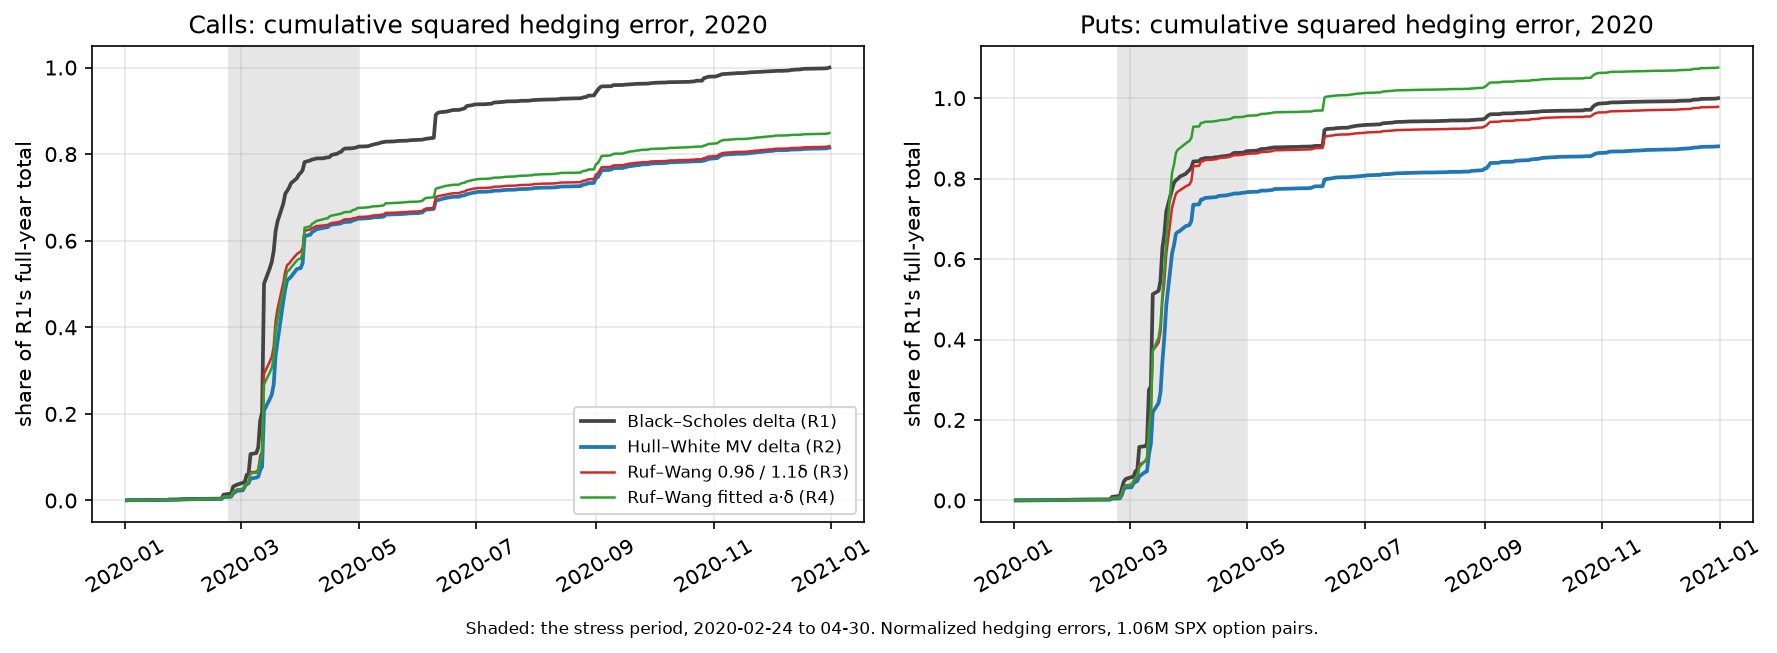

Gain of the minimum-variance delta over Black-Scholes, month by month; mean of the monthly Gains: {'calls': 0.006, 'puts': 0.003}


month,2020-01,2020-02,2020-03,2020-04,2020-05,2020-06,2020-07,2020-08,2020-09,2020-10,2020-11,2020-12
cp,,,,,,,,,,,,
calls,0.342,0.387,0.283,-0.798,0.172,0.416,0.020,-0.108,-0.573,0.271,-0.480,0.142
puts,0.394,0.403,0.147,-0.643,0.153,0.427,0.121,-0.255,-0.474,0.317,-0.544,-0.011


In [8]:
display(Image(filename=str(R / "figures/cumulative_sse_2020.png"), width=900))
m = pd.concat([pd.read_csv(R / f"2020/monthly_{cp}.csv") for cp in "CP"]).pivot(index="month", columns="cp", values="G_R2_R1")
print("Gain of the minimum-variance delta over Black-Scholes, month by month; mean of the monthly Gains:", m.mean().round(3).rename(CP).to_dict())
m.rename(columns=CP).round(3).T

**Month by month** the Gain swings from about +0.4 to −0.8, and the average of the monthly Gains (Hull and White's aggregation) is about zero. The correction helped from January to March and hurt badly in April. April's fit was the first whose 12-month window contained March 2020, and its put coefficients jumped; but in April, as in August, September and November, even a fit to that month's own data removed almost nothing, so the spot–volatility relation the rule relies on had all but vanished, and any correction could only add error (notebook 04). The crash in the window is not the whole story: May and June, with the same crash in their windows, gained, and September and November lost without a new one.

### 4.2 Years and stress episodes (detail: notebooks 06, 09 and 07)

Yearly Gains are mostly 0.10–0.25 through 2021, and about zero in 2022–2023. The table gives each year's Gain over Black–Scholes with its interval (12-month fits) and the point Gains with 36- and 60-month fits; the status column says whether the year was clean.

In [9]:
x = G[(G.rule == "R2") & (G.base == "R1")]
t = pd.DataFrame(index=sorted(x.year.unique()))
for cp in "CP":
    for W in (12, 36, 60):
        z = x[(x.cp == cp) & (x.window == W)].set_index("year")
        t[f"{CP[cp]}, {W}-month"] = z.apply(fmt, axis=1) if W == 12 else z.gain.map(lambda v: f"{v:+.3f}")
t = t.fillna("")
t["status"] = x[(x.cp == "C") & (x.window == 12)].set_index("year").status
x12 = x[x.window == 12]
print(f"12-month fits: significantly positive in {(x12.lo > 0).sum()} of {len(x12)} call-or-put years, significantly negative in {(x12.hi < 0).sum()}")
print("median yearly Gain, 2015-2023:", {f"{W}-month": median_1523("R2", "R1", W).round(3).rename(CP).to_dict() for W in (12, 36, 60)})
t

12-month fits: significantly positive in 7 of 26 call-or-put years, significantly negative in 0
median yearly Gain, 2015-2023: {'12-month': {'calls': 0.124, 'puts': 0.1}, '36-month': {'calls': 0.157, 'puts': 0.158}, '60-month': {'calls': 0.157, 'puts': 0.16}}


,"calls, 12-month","calls, 36-month","calls, 60-month","puts, 12-month","puts, 36-month","puts, 60-month",status
2011,"+0.242 [-0.01, +0.35]",,,"+0.152 [+0.02, +0.33] *",,,untouched
2012,"+0.031 [-0.20, +0.20]",,,"+0.092 [-0.05, +0.20]",,,untouched
2013,"+0.151 [-0.01, +0.25]",+0.135,,"+0.155 [-0.01, +0.24]",+0.154,,untouched
2014,"+0.188 [+0.03, +0.32] *",+0.201,,"+0.207 [+0.07, +0.32] *",+0.218,,fit-only (2019 dry run)
2015,"+0.253 [+0.11, +0.34] *",+0.256,+0.255,"+0.276 [+0.11, +0.34] *",+0.272,+0.287,fit-only
2016,"+0.181 [-0.00, +0.29]",+0.186,+0.175,"+0.152 [-0.05, +0.27]",+0.168,+0.171,fit-only
2017,"+0.124 [-0.09, +0.27]",+0.116,+0.114,"+0.052 [-0.20, +0.20]",+0.020,+0.024,fit-only
2018,"+0.033 [-0.32, +0.21]",+0.133,+0.141,"+0.056 [-0.13, +0.17]",+0.188,+0.192,evaluated (rehearsal)
2019,"+0.116 [-0.05, +0.24]",+0.159,+0.161,"+0.100 [-0.25, +0.30]",+0.158,+0.160,"evaluated (rehearsal, dry run)"
2020,"+0.185 [-0.36, +0.46]",+0.178,+0.176,"+0.120 [-0.45, +0.46]",+0.142,+0.144,evaluated (unblinding)


**Reading.**
- **With 12-month fits, the Gain is significantly positive in 7 of 26 call-or-put years and significantly negative in none.** It is positive in every year through 2021.
- **The clean years agree.** 2011–2013 gain 0.03–0.24, and in 2021, a year nobody had looked at, both types gain significantly (0.15 and 0.16).
- **The advantage disappears in 2022–2023.** With 12-month fits the Gain is about zero, with tight intervals in 2023. Longer windows, which remember more of the earlier, stronger relation, lose in 2022 (−0.16 to −0.23).
- **Longer windows gain more in the typical year** (median 0.16 with 36- or 60-month fits, against 0.12 / 0.10), but pay more when the relation changes.

**Stress episodes,** defined from the S&P 500 close alone (RV: 20-day realized volatility above 25%; DD: a peak-to-trough drawdown of at least 10%), scored with the walk-forward's 12-month fits:

In [10]:
S = pd.read_csv(R / "walkforward/stress_gains.csv")
s = S[(S.window == 12) & (S.rule == "R2") & (S.base == "R1")].copy()
s["episode"] = s.start + " to " + s.end + " (" + s.definition + ")"
s["g"] = s.apply(fmt, axis=1)
s.pivot_table(index=["episode", "sessions"], columns="cp", values="g", aggfunc="first").rename(columns=CP)

,cp,calls,puts
episode,sessions,,
2011-04-29 to 2011-10-03 (DD),107,"+0.280 [+0.09, +0.39] *","+0.137 [-0.01, +0.36]"
2011-08-08 to 2011-12-22 (RV),93,"+0.215 [-0.17, +0.39]","+0.253 [+0.10, +0.41] *"
2015-05-21 to 2016-02-11 (DD),184,"+0.278 [+0.17, +0.36] *","+0.264 [+0.08, +0.34] *"
2015-08-26 to 2015-09-23 (RV),20,"+0.224 [-0.35, +0.44]","+0.197 [-0.51, +0.54]"
2018-01-26 to 2018-02-08 (DD),10,"+0.218 [+0.12, +0.26] *","+0.109 [+0.04, +0.17] *"
2018-02-12 to 2018-03-05 (RV),15,"-0.024 [-0.60, +0.20]","+0.027 [-0.31, +0.19]"
2018-09-20 to 2018-12-24 (DD),66,"+0.011 [-0.58, +0.44]","+0.144 [-0.10, +0.40]"
2018-12-26 to 2019-01-23 (RV),19,"-0.057 [-0.71, +0.19]","-0.306 [-1.16, +0.04]"
2020-02-19 to 2020-03-23 (DD),24,"+0.330 [-0.40, +0.62]","+0.206 [-0.43, +0.58]"


**Reading.**
- **Sell-offs gain,** significantly in 2011, 2015–2016 and February 2018. Every drawdown gains for both types in its point estimate.
- **Rebounds and post-crash periods lose.** September–December 2022 loses significantly: −0.52 for calls and −0.56 for puts. Late 2018 (the rebound from the December 2018 low) and March 2022 lose too, without significance. A three-session episode at the end of September 2020 is also significantly negative for puts, but three sessions are too few for its interval to mean much.
- **Significance here is pointwise,** over 17 episodes and two types, with no adjustment for multiplicity; episode bootstraps shorten the block for short episodes.
- **So the stable-relation assumption fails in one direction of stress more than the other** (§5, notebook 09).

**SPY replicates the picture.** SPY options are American and settle into shares, and SPY pays quarterly dividends, so the replication reruns every applicable SPX procedure with Lecture 12's American tree (notebook 07). Its 2020 is also Inconclusive, as are all 10 of its robustness variants (SPX's set without A); that verdict is post hoc, because SPY's 2020 Gains were seen before the replication was specified. Puts typically gain 16–28% a year through 2021:

In [11]:
sv = pd.read_csv(R / "spy/2020/verdict.csv")
print(f"SPY 2020: {sv.verdict[0]}; calls {sv.G_C[0]:+.3f} [{sv.G_C_lo[0]:+.2f}, {sv.G_C_hi[0]:+.2f}], puts {sv.G_P[0]:+.3f} [{sv.G_P_lo[0]:+.2f}, {sv.G_P_hi[0]:+.2f}]")
print("robustness variants:", sv.verdict[1:].value_counts().to_dict())
sg = pd.read_csv(R / "spy/walkforward/gains_by_year.csv")
z = sg[(sg.rule == "R2") & (sg.base == "R1") & (sg.window == 12)]
z.assign(g=z.apply(fmt, axis=1)).pivot(index="year", columns="cp", values="g").rename(columns=CP)

SPY 2020: Inconclusive; calls +0.104 [-0.30, +0.40], puts +0.238 [-0.25, +0.48]
robustness variants: {'Inconclusive': 10}


cp,calls,puts
year,,
2011,"+0.160 [-0.10, +0.26]","+0.232 [+0.05, +0.45] *"
2012,"+0.024 [-0.16, +0.17]","+0.244 [+0.11, +0.35] *"
2013,"+0.092 [-0.02, +0.18]","+0.279 [+0.11, +0.39] *"
2014,"+0.113 [+0.05, +0.18] *","+0.268 [+0.17, +0.36] *"
2015,"+0.137 [+0.04, +0.23] *","+0.245 [+0.06, +0.40] *"
2016,"+0.069 [-0.05, +0.15]","+0.202 [+0.03, +0.31] *"
2017,"+0.085 [-0.03, +0.18]","+0.079 [-0.18, +0.24]"
2018,"-0.078 [-0.51, +0.11]","+0.172 [+0.05, +0.25] *"
2019,"+0.013 [-0.10, +0.11]","+0.105 [-0.12, +0.26]"


### 4.3 Complex against simple rules (detail: notebooks 06 and 08)

**Against the scaling rules, year by year** (12-month fits, Gain of the minimum-variance delta over each scaling rule):

In [12]:
for base, name in (("R3", "the fixed 0.9/1.1 scaling"), ("R4", "the fitted scaling")):
    z = wf("R2", base)
    win, lose = z[z.lo > 0], z[z.hi < 0]
    print(f"Against {name}: significantly better in {len(win)} of {len(z)} call-or-put years, significantly worse in {len(lose)}"
          + (" (" + ", ".join(f"{y} {CP[c]}" for y, c in zip(lose.year, lose.cp)) + ")" if len(lose) else ""))
print("median yearly Gain over Black-Scholes, 2015-2023 (calls / puts):",
      {r: median_1523(r, "R1").round(3).tolist() for r in ("R2", "R3", "R4", "P0")})

Against the fixed 0.9/1.1 scaling: significantly better in 14 of 26 call-or-put years, significantly worse in 2 (2018 calls, 2018 puts)
Against the fitted scaling: significantly better in 12 of 26 call-or-put years, significantly worse in 0
median yearly Gain over Black-Scholes, 2015-2023 (calls / puts): {'R2': [0.124, 0.1], 'R3': [0.125, 0.099], 'R4': [0.12, 0.06], 'P0': [0.119, 0.105]}


**Reading.** The minimum-variance delta beats the fixed scaling significantly in 14 of 26 call-or-put years, and loses in two, both in 2018. The fitted scaling is significantly worse in 12 of 26, and never significantly better. Yet the fixed scaling's *median* Gain over Black–Scholes (0.125 / 0.099) matches the minimum-variance delta's: it is better in some years (2018) and much worse in others (−0.14 to −0.18 in 2022, −0.06 to −0.14 in 2023).

**The challengers.** Each row is a rule's yearly Gain over the minimum-variance delta (12-month fits, SPX), and the last column is the largest gap, in any year, between the rule's Gain over Black–Scholes and the minimum-variance delta's.

In [13]:
names = {"P0": "constant correction", "P1": "linear in delta", "P2": "quadratic (spans R2: a check)", "P3": "cubic",
         "P4": "degree 4", "P5": "degree 5", "P6": "degree 6", "P7": "degree 7", "P8": "degree 8", "PCV": "degree chosen by validation",
         "R5": "relaxed Hull-White", "R6": "delta-vega-vanna regression", "R9": "LightGBM on delta, from scratch",
         "R11": "LightGBM on delta, boosted from R2", "R10": "LightGBM on features, from scratch", "R8": "LightGBM on features, boosted from R2"}
r2 = wf("R2", "R1").set_index(["year", "cp"]).gain
rows = []
for rule, name in names.items():
    z, m = wf(rule, "R2"), median_1523(rule, "R2")
    rows.append({"code": rule, "rule": name, "median over R2, 2015-2023 (calls / puts)": f"{m['C']:+.3f} / {m['P']:+.3f}",
                 "lowest year": z.gain.min(), "highest year": z.gain.max(),
                 "significantly better / worse (of 26)": f"{(z.lo > 0).sum()} / {(z.hi < 0).sum()}",
                 "largest gap from R2 over Black-Scholes": (wf(rule, "R1").set_index(["year", "cp"]).gain - r2).abs().max()})
pd.DataFrame(rows).round(3)

,code,rule,"median over R2, 2015-2023 (calls / puts)",lowest year,highest year,significantly better / worse (of 26),largest gap from R2 over Black-Scholes
0,P0,constant correction,-0.002 / -0.001,-0.015,0.014,6 / 3,0.013
1,P1,linear in delta,-0.002 / +0.000,-0.008,0.007,4 / 9,0.008
2,P2,quadratic (spans R2: a check),-0.000 / +0.000,-0.000,0.000,2 / 4,0.000
3,P3,cubic,+0.000 / +0.000,-0.004,0.002,6 / 3,0.003
4,P4,degree 4,+0.000 / +0.000,-0.003,0.002,6 / 3,0.003
5,P5,degree 5,+0.000 / +0.000,-0.003,0.002,5 / 3,0.003
6,P6,degree 6,+0.000 / +0.000,-0.003,0.002,5 / 3,0.003
7,P7,degree 7,+0.000 / +0.000,-0.003,0.001,5 / 3,0.003
8,P8,degree 8,+0.000 / +0.000,-0.003,0.001,5 / 3,0.003
9,PCV,degree chosen by validation,+0.001 / +0.001,-0.009,0.011,5 / 0,0.010


**Reading.**
- **For SPX with 12-month fits, the constant correction, every polynomial degree and the delta-only LightGBM corrections all stay within about 0.015 a year of the minimum-variance delta.** That is under a third of the 0.05 the plan calls material, and in a typical year the gap is a few thousandths.
- **Read the significance counts with care for these close rules.** P2 spans exactly the same functions as the minimum-variance delta (its gap is about 10⁻¹⁵), yet it shows "significant" differences in 6 of 26 call-or-put years: at gaps this small, the bootstrap's marks are rounding noise.
- **The relaxed Hull–White rule equals the minimum-variance delta** to within 0.006 a year.
- **Ruf and Wang's delta–vega–vanna regression is slightly worse:** median Gains of −0.011 / −0.004 relative to the minimum-variance delta, and −0.18 for 2020 puts.
- **The LightGBM corrections that use market features fail in the crash** (below), and otherwise track the minimum-variance delta.

In [14]:
g = pd.read_csv(R / "2020/gains.csv").query("variant == 'learners (feature-complete)'").set_index(["rule", "base", "cp"]).gain
r9 = pd.read_csv(R / "2020/r9_r11.csv").query("variant == 'primary' and base == 'R1'").set_index(["rule", "cp"]).gain
for cp in "CP":
    r8 = (1 - g[("R8", "R2", cp)]) * (1 - g[("R2", "R1", cp)])  # SSE(R8)/SSE(R1), via R2 on the same pairs
    print(f"2020 {CP[cp]}: squared error relative to Black-Scholes: R8 {r8:.2f}, R10 {1 - r9[('R10', cp)]:.2f}, "
          f"R9 {1 - r9[('R9', cp)]:.2f}, R11 {1 - r9[('R11', cp)]:.2f}")

2020 calls: squared error relative to Black-Scholes: R8 0.83, R10 0.78, R9 0.81, R11 0.81
2020 puts: squared error relative to Black-Scholes: R8 9.02, R10 10.67, R9 0.88, R11 0.88


**Reading.** In 2020 the market-feature corrections' squared error for puts was 9–11 times Black–Scholes', after the crash took their features outside the training range. The trees used in March were fitted on March 2019 to February 2020, whose 20-day realized volatility never exceeded 25% and whose worst 5-day index return was −12%; March 2020 brought 98% and −20%. Trees extrapolate a constant from the edge of their training data. Calls were unaffected, and the delta-only learners, with no such features, stayed with the minimum-variance delta. The 2×2 design (from scratch or boosted, on delta or on features) therefore points to the features, not the boosting, as what broke.

### 4.4 The level and the assumption checks (detail: notebooks 09, 08 and 03)

**The level** replaces the quadratic with one constant: the hedge's assumed sensitivity of implied volatility to the index. With a constant correction c, the hedge is δ + c·ν/(S√T), so the assumed response is ∂σ/∂S = c/(S√T): a 1% index fall (ΔS = −0.01·S) raises implied volatility by −0.01·c/√T, or −c/√T volatility points. A level of −0.13 therefore means a 1% index fall raises implied volatility by 0.13 volatility points at one year to expiry, or 0.26 at three months:

In [15]:
c = -0.13
for T, label in ((1.0, "one year"), (0.25, "three months")):
    print(f"level {c}: a 1% index fall raises implied volatility by {-c / np.sqrt(T):.2f} vol points at {label} to expiry")
L = pd.read_csv(R / "walkforward/level_shape_by_year.csv")
print(f"\nlargest |R2's weighted mean correction - the constant's c|, over all years: {(L.R2_mean_correction - L.c_fit).abs().max():.1e}")
print(f"the shape (R2 over the constant) adds {L.G_shape_R2_P0.min():+.3f} to {L.G_shape_R2_P0.max():+.3f} a year")
cols = ["c_fit", "c_post", "G_level_P0_R1", "G_shape_R2_P0", "G_ceiling_P0post_R1"]
L.pivot_table(index="year", columns="cp", values=cols)[cols].rename(columns=CP, level=1).round(3)

level -0.13: a 1% index fall raises implied volatility by 0.13 vol points at one year to expiry
level -0.13: a 1% index fall raises implied volatility by 0.26 vol points at three months to expiry

largest |R2's weighted mean correction - the constant's c|, over all years: 1.2e-15
the shape (R2 over the constant) adds -0.014 to +0.015 a year


c_fit        c_post        G_level_P0_R1        G_shape_R2_P0        G_ceiling_P0post_R1       
cp    calls   puts  calls   puts         calls   puts         calls   puts               calls   puts
year                                                                                                 
2011 -0.214 -0.172 -0.159 -0.169         0.244  0.152        -0.003  0.000               0.414  0.168
2012 -0.210 -0.164 -0.119 -0.114         0.037  0.102        -0.006 -0.012               0.189  0.175
2013 -0.125 -0.118 -0.121 -0.099         0.152  0.155        -0.001 -0.001               0.266  0.257
2014 -0.126 -0.126 -0.126 -0.133         0.185  0.207         0.003  0.001               0.232  0.258
2015 -0.124 -0.140 -0.128 -0.143         0.252  0.271         0.002  0.006               0.309  0.341
2016 -0.138 -0.164 -0.105 -0.102         0.179  0.151         0.002  0.001               0.264  0.230
2017 -0.127 -0.122 -0.123  0.015         0.111  0.043         0.015  0.010               0.306  0.284
2018 -0.220 -0.255 -0.061 -0.107         0.046  0.063        -0.014 -0.007               0.323  0.341
2019 -0.100 -0.125 -0.105 -0.116         0.119  0.105        -0.003 -0.006               0.278  0.342
2020 -0.202 -0.175 -0.161 -0.145         0.190  0.120        -0.006 -0.000               0.258  0.188
2021 -0.163 -0.166 -0.191 -0.208         0.151  0.158         0.004  0.004               0.240  0.298
2022 -0.128 -0.133 -0.086 -0.054        -0.007 -0.061         0.009  0.003               0.179  0.196
2023 -0.025 -0.006 -0.041 -0.024         0.003 -0.013        -0.001 -0.001               0.043  0.109

**Reading.** In the table, `c_fit` is the fitted level (the trailing 12-month constant, averaged over the year's refits), `c_post` the best constant for that year's own pairs, after the fact; `G_level_P0_R1` the constant correction's Gain over Black–Scholes, `G_shape_R2_P0` what the quadratic shape adds to it, and `G_ceiling_P0post_R1` the Gain the best constant would have given.
- **The fitted quadratic, averaged over the training options with the regression's weights, equals the constant exactly.** That is the first normal equation of the least-squares fit (the regressor is ν/(S√T)·1, so the weighted residuals sum to zero). The match above is to rounding error.
- **The level supplies the Gain; variation across strikes adds only −0.014 to +0.015 a year.**
- **A mis-estimated level costs quadratically.** With y the Black–Scholes error and x the regressor ν·ΔS/(S²√T), the squared error of a constant c is Σy² − 2cΣxy + c²Σx², and the best constant is c* = Σxy/Σx². So the Gain of c over Black–Scholes is exactly G(c) = G*·[1 − ((c − c*)/c*)²], where G* is the ceiling. A level twice too large gives zero, and more than that loses to Black–Scholes. The identity holds for each monthly fit and its own test month, where c is a single number; the yearly columns above average twelve fits and do not satisfy it. The check, over every monthly fit of 2011–2023:

In [16]:
lm = pd.read_csv(R / "walkforward/level_shape_by_month.csv")  # one row per test month and type: the fitted c, the best c*, the sums of squares
G_c = 1 - lm.sse_P0 / lm.sse_R1
G_star = 1 - lm.sse_P0_post / lm.sse_R1
ratio = lm.c_fit / lm.c_post
print(f"{len(lm)} monthly fits; largest |G(c) - G*[1 - (1 - c/c*)^2]|: {(G_c - G_star * (1 - (1 - ratio) ** 2)).abs().max():.1e}")
print(f"fits (month x type) whose fitted level overshot the best by more than 2x: {(ratio > 2).sum()}, of which lost to Black-Scholes: {((ratio > 2) & (G_c < 0)).sum()}")
print(f"months that lost to Black-Scholes: {(G_c < 0).sum()}, of which the fitted level was more than 2x the best or of the wrong sign: {((G_c < 0) & ((ratio > 2) | (ratio < 0))).sum()}")

312 monthly fits; largest |G(c) - G*[1 - (1 - c/c*)^2]|: 7.0e-13
fits (month x type) whose fitted level overshot the best by more than 2x: 56, of which lost to Black-Scholes: 56
months that lost to Black-Scholes: 112, of which the fitted level was more than 2x the best or of the wrong sign: 112


**Reading.** Every month in which the fitted level overshot the month's best level by more than a factor of two lost to Black–Scholes, and every losing month either overshot that much or had the wrong sign. In market terms, the rule loses whenever the spot–volatility relation weakens by more than half between the fitting window and the hedging month.

**The individual coefficients are poorly identified, but the level is well identified, and it varies over time:**

In [17]:
P = pd.read_csv(R / "walkforward/parameter_stability_summary.csv")
P[P.window == 12][["cp", "rule", "coef", "refits", "min", "median", "max", "median_se", "share_abs_z12_gt_2", "median_corr_bc"]].round(3)

,cp,rule,coef,refits,min,median,max,median_se,share_abs_z12_gt_2,median_corr_bc
0,C,P0,c0,156,-0.340,-0.135,0.018,0.033,0.188,NaN
1,C,R2,a,156,-0.297,-0.200,-0.006,0.033,0.132,-0.875
2,C,R2,b,156,-0.251,0.322,0.547,0.069,0.222,-0.875
3,C,R2,c,156,-0.748,-0.355,0.014,0.092,0.264,-0.875
4,C,R4,a_hat,156,0.799,0.924,1.005,0.017,0.229,NaN
5,P,P0,c0,156,-0.357,-0.138,0.043,0.038,0.097,NaN
6,P,R2,a,156,-0.527,-0.195,0.028,0.042,0.139,0.919
7,P,R2,b,156,-0.641,-0.233,0.088,0.086,0.201,0.919
8,P,R2,c,156,-0.491,-0.139,0.120,0.088,0.139,0.919
9,P,R4,a_hat,156,0.974,1.085,1.187,0.023,0.097,NaN


**Reading.** Each row summarizes a coefficient over the 156 monthly refits of 2011–2023, with session-clustered standard errors. R2's b and c are nearly collinear (|correlation| about 0.9), so they trade off against each other; the constant's c (P0, the level) has a median standard error of about 0.03. **The level drifts:** from about −0.34 to near zero, and fits 12 months apart, on non-overlapping data, differ by more than two reported standard errors in 19% of call and 10% of put comparisons (`share_abs_z12_gt_2`). These standard errors are clustered by session but omit serial dependence across sessions, so the counts somewhat overstate the instability.

**The shape and the maturity scaling.** With 12-month fits, degrees 0–8 give essentially the same Gain (§4.3). Maturity powers $T^{-\alpha}$ for $\alpha=0,0.25,0.75,1$ never consistently beat $1/\sqrt{T}$ (counts of significant years, against $1/\sqrt{T}$):

In [18]:
M = pd.read_csv(R / "walkforward/maturity_by_year.csv").query("regime == 'all'")
M.assign(better=M.lo > 0, worse=M.hi < 0).groupby("rule").agg(
    better=("better", "sum"), worse=("worse", "sum"), type_years=("gain", "size"), median_gain_over_sqrt_T=("gain", "median")).round(3)

,better,worse,type_years,median_gain_over_sqrt_T
rule,,,,
alpha:0,1,4,26,-0.038
alpha:0.25,3,4,26,-0.009
alpha:0.75,2,8,26,-0.005
alpha:1,1,11,26,-0.029


These checks were first made before 2020 was opened, in the rehearsal (notebook 03). There $1/\sqrt{T}$ was not contradicted by any alternative power. The cubic did beat the quadratic in 2019 by the plan's pre-specified criterion, though by only about 0.2% of the squared error, and not in 2018; it was carried to 2020 as an exploratory rule and was no better there. So "not contradicted" in the table of §6 means not contradicted in any economically meaningful sense.

### 4.5 Extensions and published benchmarks (detail: notebooks 10, 11, 08 and 09)

**Books** (notebook 10). We score each day's average error across all calls, all puts, or long-volatility positions in out-of-the-money options; a risk reversal (long out-of-the-money calls, short out-of-the-money puts) is the control, because its volatility exposures cancel. Median yearly Gains over Black–Scholes, 2011–2023, on the book and per option, with each book's common share (the part of the per-option squared error that survives averaging):

In [19]:
B = pd.read_csv(R / "extensions/spx/books_median_yearly_gain.csv")
t = B[(B.base == "R1") & B.rule.isin(["R2", "R3", "R4", "P0"])].pivot_table(index="book", columns=["rule", "measure"], values="median_yearly_gain")
t[("common share", "")] = pd.read_csv(R / "extensions/spx/books_common_share.csv").groupby("book").common_share_R1.median()
display(t.round(3))
print("The fixed scaling (R3) over the minimum-variance delta, median yearly Gain:")
B[(B.base == "R2") & (B.rule == "R3")].pivot_table(index="book", columns="measure", values="median_yearly_gain").round(3)

rule              P0                R2                R3                R4            common share
measure         book per_option   book per_option   book per_option   book per_option             
book                                                                                              
calls          0.224      0.151  0.221      0.151  0.250      0.125  0.210      0.120        0.711
long_vol       0.230      0.158  0.217      0.162  0.214      0.150  0.180      0.120        0.687
puts           0.180      0.120  0.173      0.120  0.203      0.099  0.151      0.081        0.693
risk_reversal  0.061      0.158  0.041      0.162  0.052      0.150  0.039      0.120        0.119

The fixed scaling (R3) over the minimum-variance delta, median yearly Gain:


measure,book,per_option
book,,
calls,0.011,-0.037
long_vol,-0.017,-0.014
puts,0.003,-0.056
risk_reversal,-0.007,-0.014


**Reading.** For SPX calls, the median yearly Gain over 2011–2023 is 0.22 on the book against 0.15 per option, about 1.4 times (puts: 0.17 against 0.12). Losses grow too: in 2022 the put book lost 0.14 against 0.06 per option (its interval, [−0.49, +0.13], includes zero). The control gains little (0.04). The common share is a median of about 0.7 across years, ranging from 0.32 to 0.82 by book and year. **Only a book's total correction matters,** because every option's error on a day is divided by the same index level, so a book's error depends only on the average of its hedge ratios. So on books the fixed scaling roughly ties the minimum-variance delta (+0.011 / +0.003), though it trails per option (−0.037 / −0.056).

**Held positions** (notebook 10). These tests accumulate the error over 5 or 10 days, rehedging daily with each day's ratio; after the start the contract is followed whatever its delta, maturity or volume, because dropping it when it leaves the band would select on the outcome. Gains over Black–Scholes, on the path and one day at a time on the same pairs:

In [20]:
PG = pd.read_csv(R / "extensions/spx/paths_gains.csv")
z = PG[(PG.subset == "all") & (PG.base == "R1") & PG.rule.isin(["R2", "P0", "R3", "R4"]) & PG.period.isin(["2011-2019", "2020", "2021-2023"])]
z.pivot_table(index=["period", "rule"], columns=["H", "measure", "cp"], values="gain").round(3)

H                       5                                10                     
measure        one_session          path        one_session          path       
cp                       C      P      C      P           C      P      C      P
period    rule                                                                  
2011-2019 P0         0.137  0.121  0.189  0.203       0.152  0.125  0.243  0.343
          R2         0.133  0.118  0.185  0.200       0.149  0.120  0.241  0.338
          R3         0.146  0.128  0.155  0.148       0.152  0.130  0.151  0.216
          R4         0.096  0.079  0.123  0.113       0.099  0.078  0.140  0.203
2020      P0         0.149  0.100  0.257  0.272       0.200  0.121  0.341  0.395
          R2         0.137  0.098  0.256  0.277       0.177  0.116  0.313  0.385
          R3         0.144 -0.017  0.211  0.082       0.160 -0.011  0.255  0.079
          R4         0.094 -0.129  0.200  0.120       0.096 -0.092  0.213  0.141
2021-2023 P0         0.044  0.012 -0.005 -0.104       0.043 -0.003  0.032 -0.054
          R2         0.047  0.012 -0.002 -0.108       0.048 -0.002  0.018 -0.066
          R3        -0.064 -0.066 -0.165 -0.183      -0.063 -0.088 -0.176 -0.140
          R4         0.043  0.001  0.000 -0.076       0.047 -0.015 -0.012 -0.037

**Reading.** In 2011–2019 the Gain rises from 12–13% for one day to 19–20% over 5 days and 24–34% over 10 days (2020: 26–28% and 31–39%). Two reasons are likely: noise in the mid quotes cancels along a path, entering only at its two ends, and the spot–volatility move accumulates over a multi-day sell-off. Losses also grow, in 2021–2023 (puts −0.11 over 5 days). The fixed scaling gains less than the minimum-variance delta on paths.

**Data starvation** (notebook 10). These tests keep fewer options per training day, or shorten the training window. Median yearly Gain of the minimum-variance delta, 2011–2023, over Black–Scholes and over the full-data fit (`R2full`) on the same pairs; `frac` keeps a random fraction of each training session's options and `k` a fixed number per session and type (medians over five seeds), and `W1`–`W6` are windows of 1–6 months:

In [21]:
sp = pd.read_csv(R / "extensions/spx/starve_seed_spread.csv").query("span == '2011-2023' and rule == 'R2'")
order = ["W12", "frac0.25", "frac0.05", "frac0.01", "k10", "k3", "W6", "W3", "W2", "W1"]
display(sp.pivot_table(index="config", columns=["base", "cp"], values="median").loc[order].round(3))
SB = pd.read_csv(R / "extensions/spx/starve_by_year.csv")
print("2022, Gain over Black-Scholes by training window:")
SB[(SB.rule == "R2") & (SB.base == "R1") & (SB.year == 2022)].pivot_table(index="config", columns="cp", values="gain").loc[["W12", "W6", "W3", "W2", "W1"]].rename(columns=CP).round(3)

base         R1        R2full       
cp            C      P      C      P
config                              
W12       0.151  0.120  0.000  0.000
frac0.25  0.151  0.120 -0.000 -0.000
frac0.05  0.149  0.120 -0.001 -0.001
frac0.01  0.144  0.119 -0.004 -0.005
k10       0.143  0.132 -0.004  0.001
k3        0.138  0.124 -0.010 -0.007
W6        0.139  0.133 -0.014 -0.017
W3        0.143  0.104 -0.026 -0.034
W2        0.092  0.047 -0.025 -0.051
W1        0.091  0.031 -0.036 -0.071

2022, Gain over Black-Scholes by training window:


cp,calls,puts
config,,
W12,0.002,-0.058
W6,0.034,-0.010
W3,0.071,0.047
W2,0.045,0.008
W1,0.030,0.041


**Reading.** Three options of each type a day cost only about 0.01 in Gain: the information is in the number of sessions, not options, because all options on a day share its index move. Windows below three months lose 0.02–0.07 a year. Yet a three-month window would have adapted to 2022: puts go from −0.058 to +0.047. That is hindsight on one year: the same window does worse in 2021 (puts 0.104 against 0.161) and 2023 (−0.060 against −0.014). No window is best every year: a long one estimates the level precisely but goes stale, a short one tracks it but is noisy.

**Stocks and ETFs** (notebook 11). The SPY protocol on AAPL, NVDA and TSLA (single stocks), QQQ (a Nasdaq-100 ETF) and SLV (a silver ETF). Median yearly Gains over Black–Scholes of the minimum-variance delta (R2) and the fixed scaling (R3); the 12-, 36- and 60-month medians cover 2017–2023, 2019–2023 and 2021–2023:

In [22]:
m = pd.concat([pd.read_csv(R / f"stocks/{u}/walkforward_median_yearly_gain.csv").assign(underlying=u.upper()) for u in ("aapl", "nvda", "tsla", "qqq", "slv")])
m[(m.base == "R1") & m.rule.isin(["R2", "R3"])].pivot_table(index="underlying", columns=["rule", "window", "cp"], values="median_yearly_gain").round(3)

rule           R2                                        R3                                   
window         12            36            60            12            36            60       
cp              C      P      C      P      C      P      C      P      C      P      C      P
underlying                                                                                    
AAPL        0.044  0.015  0.060  0.013  0.023  0.016 -0.052 -0.034 -0.018 -0.034 -0.171 -0.034
NVDA       -0.025 -0.093 -0.007 -0.008 -0.060 -0.076 -0.192 -0.143 -0.192 -0.143 -0.305 -0.270
QQQ         0.083  0.059  0.055  0.056 -0.087 -0.000  0.067  0.010 -0.055  0.008 -0.102 -0.042
SLV        -0.000 -0.010 -0.030 -0.020  0.002  0.012 -0.104 -0.122 -0.106 -0.182 -0.106 -0.182
TSLA       -0.046 -0.034 -0.008 -0.013  0.012  0.013 -0.372 -0.223 -0.386 -0.223 -0.422 -0.267

**Reading.** AAPL gains a little; NVDA, TSLA and SLV gain nothing or lose; and QQQ behaves like SPX on 12- and 36-month fits (its 60-month median, −0.09 for calls, rests on 2021–2023 alone, the years SPX's Gain faded too). The fixed 0.9/1.1 scaling, read off S&P 500 options, loses 0.05–0.37 for calls on the three stocks with 12-month fits. Hull and White also found much smaller Gains for single stocks (Dow stocks, 2004–2015: 10.3% for calls and 2.5% for puts).

**Short-dated options** (notebook 08): options under 14 days, with the main study's coefficients.

In [23]:
sd = pd.read_csv(R / "short_dated/gains_by_year.csv")
print("median yearly Gain over Black-Scholes, 2015-2023:",
      sd[(sd.rule == "R2m") & (sd.base == "R1") & sd.year.between(2015, 2023)].groupby("cp").gain.median().round(3).rename(CP).to_dict())
print("by days to expiry on day one, median over 2011-2023:")
pd.read_csv(R / "short_dated/buckets.csv").groupby(["days", "cp"]).G_R2m_R1.median().unstack().rename(columns=CP).round(3)

median yearly Gain over Black-Scholes, 2015-2023: {'calls': 0.061, 'puts': 0.005}
by days to expiry on day one, median over 2011-2023:


cp,calls,puts
days,,
0-2,0.003,-0.016
3-6,0.025,-0.022
7-13,0.087,0.033


**Reading.** Options under 14 days gain 0.06 / 0.005 for calls / puts, and about zero under three days; the 7–13-day calls do best (0.087). Why the Gain fades is not tested here. The correction itself does not vanish near expiry: ν/(S√T) is the normal density at d₁, so at the money it stays near 0.4. More likely, other parts of the error, gamma's above all, grow as expiry nears, and the coefficients come from options of 14 days or more.

**The published benchmarks** (notebook 09). Our Gains on Hull and White's test months that we also have (2013–2015 with 36-month fits; 2011–2015 with 12-month fits), pooled and as a mean of monthly Gains, which is their aggregation:

In [24]:
P = pd.read_csv(R / "walkforward/published_comparison.csv")
P[(P.rule == "R2") & (P.period == "HW overlap") & (P["sample"] == "analysis (E7)")].pivot_table(index="window", columns="cp", values=["pooled", "mean_of_monthly", "months"]).rename(columns=CP, level=1).round(3)

mean_of_monthly        months       pooled       
cp               calls   puts  calls  puts  calls   puts
window                                                  
12               0.095  0.100   60.0  60.0  0.211  0.195
36               0.101  0.094   36.0  36.0  0.221  0.249

**Reading.** Our pooled 2013–2015 Gains with 36-month fits are 0.22 / 0.25, while Hull and White report mean monthly Gains of 0.26 / 0.23 over 2007–2015. On their aggregation ours are lower still (0.10 / 0.09), so pooling is not what lowers theirs relative to ours; the periods differ, and their 2007–2012 is not in our data. Our lower headline reflects:
- **the period:** 2017, 2018 and 2022–2023 are weak years;
- **the 12-month window:** pooled over mid-2012 to mid-2019 it gives about half the 36-month Gain (0.08 against 0.14–0.17), though over the 2015–2023 medians the ratio is 0.6–0.8;
- **in-the-money calls,** about half of our call sample (55% in 2020; notebook 01): restricting to out-of-the-money options raises the pooled 2011–2019 Gain, but only modestly (calls 0.119 → 0.130, puts 0.112 → 0.132; notebook 09).

## 5. Financial interpretation

**The correction hedges the expected volatility response.** About 70% of an option's squared error is shared by all options on the day and survives averaging across a book (the common share in §4.5), which explains the larger book Gain. The size of the response matters more than its shape across strikes (§4.4). The table puts the measured response beside the yearly Gain: for near-the-money options (|δ| 0.4–0.6) 20–60 days from expiry, the slope of the daily change in implied volatility on the index return, in volatility points per 1% index fall.

correlation of the measured response with the yearly Gain:

 {'Gain, calls': 0.56, 'Gain, puts': 0.64} ; without 2022-2023: {'Gain, calls': 0.21, 'Gain, puts': 0.27}
correlation of the measured response with the best level: {'best level, calls': -0.61, 'best level, puts': -0.85}


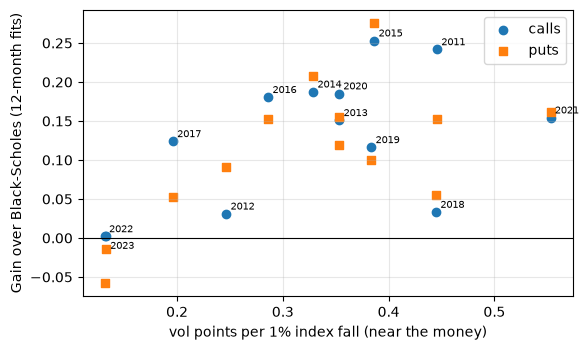

,vol_points_per_1pct_fall,"Gain, calls","Gain, puts","best level, calls","best level, puts"
year,,,,,
2011,0.446,0.242,0.152,-0.159,-0.169
2012,0.247,0.031,0.092,-0.119,-0.114
2013,0.353,0.151,0.155,-0.121,-0.099
2014,0.329,0.188,0.207,-0.126,-0.133
2015,0.387,0.253,0.276,-0.128,-0.143
2016,0.286,0.181,0.152,-0.105,-0.102
2017,0.196,0.124,0.052,-0.123,0.015
2018,0.445,0.033,0.056,-0.061,-0.107
2019,0.384,0.116,0.100,-0.105,-0.116


In [25]:
sv = pd.read_csv(R / "walkforward/spot_vol_slope.csv").set_index("year")[["vol_points_per_1pct_fall"]]
gy = wf("R2", "R1").pivot(index="year", columns="cp", values="gain").rename(columns=lambda c: f"Gain, {CP[c]}")
cp_ = L.pivot(index="year", columns="cp", values="c_post").rename(columns=lambda c: f"best level, {CP[c]}")
t = sv.join(gy).join(cp_)
print("correlation of the measured response with the yearly Gain:", t.corr().iloc[0, 1:3].round(2).to_dict(),
      "; without 2022-2023:", t.drop([2022, 2023]).corr().iloc[0, 1:3].round(2).to_dict())
print("correlation of the measured response with the best level:", t.corr().iloc[0, 3:].round(2).to_dict())
fig, ax = plt.subplots(figsize=(6, 3.6))
for cp, mk in (("C", "o"), ("P", "s")):
    ax.scatter(t.vol_points_per_1pct_fall, t[f"Gain, {CP[cp]}"], marker=mk, label=CP[cp])
for yr, r in t.iterrows():
    ax.annotate(str(yr), (r.vol_points_per_1pct_fall, r["Gain, calls"]), fontsize=7, xytext=(3, -9 if yr == 2023 else 3), textcoords="offset points")
ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("vol points per 1% index fall (near the money)"); ax.set_ylabel("Gain over Black-Scholes (12-month fits)")
ax.legend(); plt.tight_layout(); plt.show()
t.round(3)

**Reading.** For near-the-money options 20–60 days from expiry, the measured response fell from 0.55 volatility points per 1% index fall in 2021 to 0.13 in 2022–2023, and the Gain fell with it. The best level after the fact tracks the measured response (correlation −0.61 for calls, −0.85 for puts); the fitted level, learned from the stronger years before, overshot it. This is a descriptive reading, consistent with the identity of §4.4 but not a test: across years the response and the Gain correlate at 0.56 / 0.64, and at only 0.21 / 0.27 without 2022–2023. 2017, the earlier low-response year (0.20), had the smallest put Gain before 2022 (0.05).

The scatter also shows that a strong response is not enough: what matters is whether the *fitted* level matches the year's. 2018 had a strong response (0.44) but small Gains: after the February 2018 spike entered the training window, the fitted level (−0.22 for calls, −0.26 for puts, averaged over the year's refits) overshot the year's best (−0.06 and −0.11; the table in §4.4).

**Drift.** For one-day hedges, we follow Hull and White's specification, with no intercept and no theta adjustment (theta is the option's time decay, Lecture 6). Subtracting one day's theta changes the 2020 Gains by at most 0.011:

In [26]:
g = pd.read_csv(R / "2020/gains.csv")
z = g[g.variant.isin(["primary", "T"]) & (g.rule == "R2") & (g.base == "R1")].pivot(index="cp", columns="variant", values="gain").rename(index=CP)
z["T - primary"] = z["T"] - z["primary"]
display(z.round(3))
ME = pd.read_csv(R / "extensions/spx/paths_mean_error.csv")
q = ME[(ME.subset == "all") & (ME.rule == "R2") & (ME.period == "2011-2019")].set_index(["H", "cp"])[["diff_vs_R1", "diff_lo", "diff_hi"]]
print("Mean held-position error, minimum-variance delta minus Black-Scholes, 2011-2019, in basis points of the start-day index level:")
(q * 1e4).round(2)

variant,T,primary,T - primary
cp,,,
calls,0.174,0.185,-0.011
puts,0.112,0.120,-0.008


Mean held-position error, minimum-variance delta minus Black-Scholes, 2011-2019, in basis points of the start-day index level:


diff_vs_R1  diff_lo  diff_hi
H  cp                              
5  C         0.88    -0.17     1.83
   P         0.96    -0.29     2.05
10 C         1.51    -0.58     3.36
   P         1.52    -0.93     3.67

**Reading.** For the long-option position that $e$ represents, the correction leaves the position slightly longer the index, because it under-hedges calls and over-hedges puts (the fitted level is negative). Its five-day mean error exceeds Black–Scholes' by about 0.9 basis points of the index level in 2011–2019. That is consistent with earning some of the index's upward drift, and the difference is not significant (the intervals include zero).

**What a Gain is worth.** If the mean P&L is unchanged, and the reduction in squared error approximates the reduction in variance, a Gain $g$ multiplies the hedged position's Sharpe ratio (mean P&L over its standard deviation) by about $1/\sqrt{1-g}$:

In [27]:
for g in (0.10, 0.15, 0.25):
    print(f"Gain {g:.2f}: Sharpe ratio multiplied by about {1 / np.sqrt(1 - g):.2f}")

Gain 0.10: Sharpe ratio multiplied by about 1.05
Gain 0.15: Sharpe ratio multiplied by about 1.08
Gain 0.25: Sharpe ratio multiplied by about 1.15


**Where it works and fails.** Here the slope is the number of volatility points by which implied volatility rises per 1% fall in the index.
- **Works:** index options (SPX, SPY, QQQ); sell-offs; years in which the slope stays close to the preceding year's; books and held positions.
- **Fails:** after a crash enters the training window (April 2020); in rebounds and post-crash periods (late 2018, late 2022); when the slope weakens (2022–2023); on single stocks and silver; near expiry.

## 6. Assumptions, limitations and failure modes

| Assumption | Check | Result | Notebook |
|---|---|---|---|
| Volatility response is quadratic in delta | Degrees 0–8, a validated degree, LightGBM on delta | Not contradicted; shape barely matters | 03, 08 |
| Response scales as $1/\sqrt{T}$ | $T^{-\alpha}$, $\alpha\in\{0,0.25,0.75,1\}$, by year | Not beaten consistently | 03, 09 |
| Coefficients remain stable between windows | Coefficient paths; fits 12 months apart | Fails: the level drifts, badly in 2022 | 04, 09 |
| No intercept or theta term is needed | Theta-adjusted 2020 variant; held-position mean error | 2020 Gains change by at most 0.011 with theta adjustment; five-day mean-error difference from Black–Scholes about +0.9 bp in 2011–2019, not significant | 05, 10 |
| One day is the relevant horizon | 5- and 10-day held positions | Gain grows over longer horizons | 10 |
| Mid quotes are synchronous with the index | Two index-level sensitivities; bid and ask marks | Verdict unchanged | 02, 04, 05 |
| Frictionless index hedging | Turnover only | Not tested with costs; in 2020 the minimum-variance delta's daily change in hedge ratio was 3% smaller than Black–Scholes' | 05 |

**Limitations.**
- **There is one confirmatory year, and it contains a crash.** The other analyses are exploratory, and clean years are few.
- **One data vendor,** whose quote timing is undocumented; no transaction or financing costs.
- **The intervals omit the training window's estimation error,** and a crash strains the bootstrap's assumptions.
- **SPY's held-position test follows a contract only through days on which it traded with at least 14 days to expiry,** because SPY's Greeks were computed only for day-one candidates; the five stocks and ETFs use the vendor's underlying levels.

**The observed failure modes:**
- a crash entering the training window, followed by over-correction: April 2020, and the stocks' 2020 (notebooks 04 and 11);
- the LightGBM corrections with market features extrapolating outside their training range in March 2020 (notebooks 05 and 08);
- a fixed scaling of delta applied outside the market and period it was read from. Ruf and Wang's 0.9/1.1 comes from S&P 500 options from 2010 to mid-2019. It fails on SPY calls and single stocks, and on SPX itself in 2022–2023, as the volatility response weakened (notebooks 06, 07 and 11).

**What a validator would monitor** (a reading, not a tested rule): the realized Gain over Black–Scholes, monthly; the fitted level against the level recent hedges reward, since by §4.4's identity a month in which the fitted level is more than twice the rewarded one loses to Black–Scholes; and the near-the-money spot–volatility slope.

**A note on "not contradicted"** in the first row: the rehearsal's pre-specified test did prefer a cubic to the quadratic in 2019, by about 0.2% of the squared error (notebook 03); every later check found the shape economically irrelevant.

## 7. Reproducibility

The repository is [github.com/biswajit-nag/hull-white-delta-spx](https://github.com/biswajit-nag/hull-white-delta-spx). `uv sync --locked`, `uv run pytest` and `uv run python -I scripts/make_notebooks.py` rebuild every notebook, this one included, from the committed tables, without the vendor data. With the vendor's archives, the scripts in `scripts/` rebuild those tables; `REPRODUCING.md` gives every step, and `results/runtime_log.csv` records each run's commit and wall time.

This is an individual project. Claude (Anthropic) assisted with code, analysis and drafting. GPT-6 Astra (OpenAI) reviewed key steps and helped in wording the reports. The author directed the work and takes the responsibility for its correctness.

**References.** Hull, J. and White, A. (2017), Optimal delta hedging for options, *Journal of Banking & Finance* 82, 180–190. Ruf, J. and Wang, W. (2022), Hedging with linear regressions and neural networks, *Journal of Business & Economic Statistics* 40(4), 1442–1454.